<a href="https://colab.research.google.com/github/Mushfika123/Assignment/blob/main/Maternal_Health_Risk_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, accuracy_score, f1_score, recall_score
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')

# ====================== LOAD DATA ======================
df = pd.read_csv("Maternal_Risk_DUET_Cleaned.csv")
print("DUET Shape:", df.shape)
print(df['RiskLevel'].value_counts())

# ====================== ENCODING ======================
le = LabelEncoder()
df['RiskLevel'] = le.fit_transform(df['RiskLevel'])
# 0 = high risk, 1 = low risk, 2 = mid risk  (check with le.classes_)

X = df.drop('RiskLevel', axis=1)
y = df['RiskLevel']

# ====================== TRAIN-TEST SPLIT ======================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTrain shape:", X_train.shape)
print("Test shape:", X_test.shape)

# ====================== SCALING ======================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ====================== OPTIONAL: SMOTE ======================
# smote = SMOTE(random_state=42)
# X_train_scaled, y_train = smote.fit_resample(X_train_scaled, y_train)

print("\n✅ DUET Train & Test data ready!")

DUET Shape: (6102, 11)
RiskLevel
high risk    2059
mid risk     2043
low risk     2000
Name: count, dtype: int64

Train shape: (4881, 10)
Test shape: (1221, 10)

✅ DUET Train & Test data ready!


In [ ]:
# ====================== LOAD UCI DATA ======================
df_uci = pd.read_csv("UCI_Maternal_Health_Risk_Cleaned.csv")
print("UCI Shape:", df_uci.shape)
print(df_uci['RiskLevel'].value_counts())

# ====================== ENCODING ======================
le_uci = LabelEncoder()
df_uci['RiskLevel'] = le_uci.fit_transform(df_uci['RiskLevel'])

X_uci = df_uci.drop('RiskLevel', axis=1)
y_uci = df_uci['RiskLevel']

# ====================== TRAIN-TEST SPLIT ======================
X_train_uci, X_test_uci, y_train_uci, y_test_uci = train_test_split(
    X_uci, y_uci, test_size=0.2, random_state=42, stratify=y_uci
)

# ====================== SCALING ======================
scaler_uci = StandardScaler()
X_train_uci_scaled = scaler_uci.fit_transform(X_train_uci)
X_test_uci_scaled = scaler_uci.transform(X_test_uci)

print("\n✅ UCI Train & Test data ready!")

UCI Shape: (1012, 9)
RiskLevel
low risk     404
mid risk     336
high risk    272
Name: count, dtype: int64

✅ UCI Train & Test data ready!


In [ ]:
!pip install catboost lightgbm xgboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.1 MB/s eta 0:00:00


In [ ]:
# ============================================================
# Cross-Dataset: Train on DUET → Test on UCI (FIXED)
# ============================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# ====================== LOAD DATA ======================
df_duet = pd.read_csv("Maternal_Risk_DUET_Cleaned.csv")
df_uci  = pd.read_csv("UCI_Maternal_Health_Risk_Cleaned.csv")

print("DUET columns:", df_duet.columns.tolist())
print("UCI  columns:", df_uci.columns.tolist())

# ====================== SELECT COMMON FEATURES ======================
# দুই ডেটাসেটে যেগুলো common আছে শুধু সেগুলোই ব্যবহার করব
common_features = ['Age', 'SystolicBP', 'DiastolicBP', 'BodyTemp', 'HeartRate']

print("\nUsing common features:", common_features)

# ====================== PREPARE DUET (TRAIN) ======================
le = LabelEncoder()
df_duet['RiskLevel'] = le.fit_transform(df_duet['RiskLevel'])

X_train = df_duet[common_features]
y_train = df_duet['RiskLevel']

# ====================== PREPARE UCI (TEST) ======================
df_uci['RiskLevel'] = df_uci['RiskLevel'].str.strip().str.lower()
df_uci['RiskLevel'] = le.transform(df_uci['RiskLevel'])   # same encoding

X_test = df_uci[common_features]
y_test = df_uci['RiskLevel']

print(f"\nTrain shape (DUET): {X_train.shape}")
print(f"Test  shape (UCI) : {X_test.shape}")

# ====================== SCALING ======================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("✅ Scaling successful! No feature mismatch error.")

# ====================== MODELS ======================
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=7,
                      random_state=42, n_jobs=-1, verbose=-1)

cat = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=7,
                         random_state=42, verbose=0)

xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                    random_state=42, n_jobs=-1, eval_metric='mlogloss')

stacking = StackingClassifier(
    estimators=[('lgbm', lgbm), ('cat', cat), ('xgb', xgb)],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5, n_jobs=-1
)

# ====================== TRAIN & EVALUATE ======================
models = {
    "LightGBM": lgbm,
    "CatBoost": cat,
    "XGBoost": xgb,
    "Stacking": stacking
}

print("\n" + "="*60)
print("Cross-Dataset Results (Train: DUET → Test: UCI)")
print("="*60)

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='weighted')

    print(f"\n{name}:")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  F1-Score : {f1:.4f}")

print("\n✅ Cross-dataset evaluation completed successfully!")

DUET columns: ['Age', 'BodyTemp', 'HeartRate', 'SystolicBP', 'DiastolicBP', 'PulsePressure', 'MAP', 'BMI', 'HbA1c', 'FastingGlucose', 'RiskLevel']
UCI  columns: ['Age', 'SystolicBP', 'DiastolicBP', 'PulsePressure', 'MAP', 'BS', 'BodyTemp', 'HeartRate', 'RiskLevel']

Using common features: ['Age', 'SystolicBP', 'DiastolicBP', 'BodyTemp', 'HeartRate']

Train shape (DUET): (6102, 5)
Test  shape (UCI) : (1012, 5)
✅ Scaling successful! No feature mismatch error.

Cross-Dataset Results (Train: DUET → Test: UCI)

LightGBM:
  Accuracy : 0.2826
  F1-Score : 0.1832

CatBoost:
  Accuracy : 0.3103
  F1-Score : 0.2369

XGBoost:
  Accuracy : 0.3103
  F1-Score : 0.2286

Stacking:
  Accuracy : 0.3093
  F1-Score : 0.2101

✅ Cross-dataset evaluation completed successfully!


In [ ]:
# ============================================================
# Maternal Health Risk Prediction
# Hybrid Ensemble: LightGBM + CatBoost + Stacking
# ============================================================

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             roc_auc_score)
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

# ============================================================
# 1. LOAD DATA
# ============================================================
df = pd.read_csv("Maternal_Risk_DUET_Cleaned.csv")
print("Dataset Shape:", df.shape)
print("\nRiskLevel Distribution:")
print(df['RiskLevel'].value_counts())

# ============================================================
# 2. PREPROCESSING
# ============================================================
le = LabelEncoder()
df['RiskLevel'] = le.fit_transform(df['RiskLevel'])
print("\nClasses:", le.classes_)   # check mapping

X = df.drop('RiskLevel', axis=1)
y = df['RiskLevel']

# Train-Test Split (80/20 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTrain size: {X_train.shape[0]}")
print(f"Test size : {X_test.shape[0]}")

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ============================================================
# 3. DEFINE BASE MODELS
# ============================================================
lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=7,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

catboost = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=7,
    random_state=42,
    verbose=0,
    thread_count=-1
)

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss'
)

# ============================================================
# 4. STACKING ENSEMBLE
# ============================================================
estimators = [
    ('lgbm', lgbm),
    ('catboost', catboost),
    ('xgb', xgb)
]

stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5,
    n_jobs=-1,
    passthrough=False
)

# ============================================================
# 5. TRAIN MODELS
# ============================================================
print("\n" + "="*60)
print("Training Individual Models...")
print("="*60)

# LightGBM
lgbm.fit(X_train_scaled, y_train)
y_pred_lgbm = lgbm.predict(X_test_scaled)

# CatBoost
catboost.fit(X_train_scaled, y_train)
y_pred_cat = catboost.predict(X_test_scaled)

# XGBoost
xgb.fit(X_train_scaled, y_train)
y_pred_xgb = xgb.predict(X_test_scaled)

print("\nTraining Stacking Ensemble...")
stacking_model.fit(X_train_scaled, y_train)
y_pred_stack = stacking_model.predict(X_test_scaled)

# ============================================================
# 6. EVALUATION FUNCTION
# ============================================================
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n{'='*60}")
    print(f"Results for: {model_name}")
    print(f"{'='*60}")
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, average='weighted'):.4f}")
    print(f"Recall   : {recall_score(y_true, y_pred, average='weighted'):.4f}")
    print(f"F1-Score : {f1_score(y_true, y_pred, average='weighted'):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=le.classes_))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# ============================================================
# 7. SHOW RESULTS
# ============================================================
evaluate_model(y_test, y_pred_lgbm, "LightGBM")
evaluate_model(y_test, y_pred_cat, "CatBoost")
evaluate_model(y_test, y_pred_xgb, "XGBoost")
evaluate_model(y_test, y_pred_stack, "Stacking Ensemble (LGBM + CatBoost + XGB)")

# ============================================================
# 8. HIGH-RISK CLASS FOCUS (Important for Thesis)
# ============================================================
print("\n" + "="*60)
print("High-Risk Class Performance (Most Important)")
print("="*60)

# Find high risk index
high_risk_idx = list(le.classes_).index('high risk')

for name, pred in [('LightGBM', y_pred_lgbm),
                   ('CatBoost', y_pred_cat),
                   ('XGBoost', y_pred_xgb),
                   ('Stacking', y_pred_stack)]:

    recall_high = recall_score(y_test, pred, labels=[high_risk_idx], average=None)[0]
    print(f"{name:12} → High-Risk Recall: {recall_high:.4f}")

print("\n✅ Training & Evaluation Completed Successfully!")

Dataset Shape: (6102, 11)

RiskLevel Distribution:
RiskLevel
high risk    2059
mid risk     2043
low risk     2000
Name: count, dtype: int64

Classes: ['high risk' 'low risk' 'mid risk']

Train size: 4881
Test size : 1221

Training Individual Models...

Training Stacking Ensemble...

Results for: LightGBM
Accuracy : 0.9910
Precision: 0.9910
Recall   : 0.9910
F1-Score : 0.9910

Classification Report:
              precision    recall  f1-score   support

   high risk       0.99      0.99      0.99       412
    low risk       1.00      0.99      0.99       400
    mid risk       0.98      1.00      0.99       409

    accuracy                           0.99      1221
   macro avg       0.99      0.99      0.99      1221
weighted avg       0.99      0.99      0.99      1221

Confusion Matrix:
[[406   0   6]
 [  2 397   1]
 [  1   1 407]]

Results for: CatBoost
Accuracy : 0.9902
Precision: 0.9902
Recall   : 0.9902
F1-Score : 0.9902

Classification Report:
              precision    recall

In [ ]:
# ============================================================
# SHAP Explainability - Most Stable Version
# ============================================================

import shap
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

print("Generating SHAP values...")

explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test_scaled)

# ----------------------------------------------------------
# 1. Summary Plot
# ----------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=list(X.columns),
    class_names=list(le.classes_),
    show=False
)
plt.title("SHAP Summary Plot", fontsize=14)
plt.tight_layout()
plt.savefig("shap_summary_plot.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ shap_summary_plot.png saved")

# ----------------------------------------------------------
# 2. Bar Plot
# ----------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=list(X.columns),
    class_names=list(le.classes_),
    plot_type="bar",
    show=False
)
plt.title("SHAP Feature Importance (Bar)", fontsize=14)
plt.tight_layout()
plt.savefig("shap_bar_plot.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ shap_bar_plot.png saved")

# ----------------------------------------------------------
# 3. Waterfall Plot (Force Plot এর বিকল্প - অনেক Stable)
# ----------------------------------------------------------
high_risk_idx = list(le.classes_).index('high risk')
high_risk_samples = np.where(y_test == high_risk_idx)[0]

if len(high_risk_samples) > 0:
    sample_idx = high_risk_samples[0]

    # Waterfall plot is more reliable than force_plot for multi-class
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values[high_risk_idx][sample_idx],
            base_values=explainer.expected_value[high_risk_idx],
            data=X_test_scaled[sample_idx],
            feature_names=list(X.columns)
        ),
        show=False
    )
    plt.title("SHAP Waterfall Plot - High Risk Patient", fontsize=13)
    plt.tight_layout()
    plt.savefig("shap_waterfall_highrisk.png", dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ shap_waterfall_highrisk.png saved")
else:
    print("No high-risk sample found.")

print("\n✅ SHAP Explainability Completed Successfully!")

In [ ]:
# ============================================================
# Cross-Dataset Evaluation
# Train on DUET (Primary) → Test on UCI (Secondary)
# ============================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

print("="*60)
print("Cross-Dataset Evaluation: Train on DUET → Test on UCI")
print("="*60)

# ============================================================
# 1. LOAD BOTH DATASETS
# ============================================================
df_duet = pd.read_csv("Maternal_Risk_DUET_Cleaned.csv")
df_uci  = pd.read_csv("UCI_Maternal_Health_Risk_Cleaned.csv")

print(f"DUET shape: {df_duet.shape}")
print(f"UCI  shape: {df_uci.shape}")

# ============================================================
# 2. ALIGN FEATURES (Important!)
# ============================================================
# Common features between both datasets
common_features = ['Age', 'SystolicBP', 'DiastolicBP', 'BodyTemp', 'HeartRate']

# DUET has extra features, UCI has 'BS'
# We will use only common features for fair cross-dataset test

print("\nUsing common features:", common_features)

# ============================================================
# 3. PREPARE DUET (TRAIN)
# ============================================================
le = LabelEncoder()
df_duet['RiskLevel'] = le.fit_transform(df_duet['RiskLevel'])

X_train = df_duet[common_features]
y_train = df_duet['RiskLevel']

# ============================================================
# 4. PREPARE UCI (TEST)
# ============================================================
# Make sure UCI RiskLevel uses same encoding
df_uci['RiskLevel'] = df_uci['RiskLevel'].str.strip().str.lower()
df_uci['RiskLevel'] = le.transform(df_uci['RiskLevel'])

X_test = df_uci[common_features]
y_test = df_uci['RiskLevel']

print(f"\nTrain (DUET) size: {X_train.shape}")
print(f"Test  (UCI)  size: {X_test.shape}")
print("Classes:", le.classes_)

# ============================================================
# 5. SCALING
# ============================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ============================================================
# 6. DEFINE MODELS
# ============================================================
lgbm = LGBMClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=7,
    random_state=42, n_jobs=-1, verbose=-1
)

catboost = CatBoostClassifier(
    iterations=300, learning_rate=0.05, depth=7,
    random_state=42, verbose=0
)

xgb = XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=6,
    random_state=42, n_jobs=-1, eval_metric='mlogloss'
)

# Stacking
estimators = [('lgbm', lgbm), ('catboost', catboost), ('xgb', xgb)]
stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5, n_jobs=-1
)

# ============================================================
# 7. TRAIN ON DUET & TEST ON UCI
# ============================================================
print("\nTraining models on DUET...")

models = {
    "LightGBM": lgbm,
    "CatBoost": catboost,
    "XGBoost": xgb,
    "Stacking": stacking
}

results = {}

for name, model in models.items():
    print(f"  → Training {name}...")
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec  = recall_score(y_test, y_pred, average='weighted')
    f1   = f1_score(y_test, y_pred, average='weighted')

    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "Predictions": y_pred
    }

    print(f"     Accuracy: {acc:.4f} | F1: {f1:.4f}")

# ============================================================
# 8. DETAILED RESULTS
# ============================================================
print("\n" + "="*60)
print("CROSS-DATASET RESULTS (Train: DUET → Test: UCI)")
print("="*60)

for name, res in results.items():
    print(f"\n{name}:")
    print(f"  Accuracy : {res['Accuracy']:.4f}")
    print(f"  Precision: {res['Precision']:.4f}")
    print(f"  Recall   : {res['Recall']:.4f}")
    print(f"  F1-Score : {res['F1-Score']:.4f}")

# Best model detailed report
best_model_name = max(results, key=lambda x: results[x]['F1-Score'])
print(f"\n{'='*60}")
print(f"Best Model: {best_model_name}")
print(f"{'='*60}")
print(classification_report(y_test, results[best_model_name]['Predictions'],
                          target_names=le.classes_))
print("Confusion Matrix:")
print(confusion_matrix(y_test, results[best_model_name]['Predictions']))

print("\n✅ Cross-Dataset Evaluation Completed!")

Cross-Dataset Evaluation: Train on DUET → Test on UCI
DUET shape: (6102, 11)
UCI  shape: (1012, 9)

Using common features: ['Age', 'SystolicBP', 'DiastolicBP', 'BodyTemp', 'HeartRate']

Train (DUET) size: (6102, 5)
Test  (UCI)  size: (1012, 5)
Classes: ['high risk' 'low risk' 'mid risk']

Training models on DUET...
  → Training LightGBM...
     Accuracy: 0.2826 | F1: 0.1832
  → Training CatBoost...
     Accuracy: 0.3103 | F1: 0.2369
  → Training XGBoost...
     Accuracy: 0.3103 | F1: 0.2286
  → Training Stacking...
     Accuracy: 0.3093 | F1: 0.2101

CROSS-DATASET RESULTS (Train: DUET → Test: UCI)

LightGBM:
  Accuracy : 0.2826
  Precision: 0.3352
  Recall   : 0.2826
  F1-Score : 0.1832

CatBoost:
  Accuracy : 0.3103
  Precision: 0.4124
  Recall   : 0.3103
  F1-Score : 0.2369

XGBoost:
  Accuracy : 0.3103
  Precision: 0.4039
  Recall   : 0.3103
  F1-Score : 0.2286

Stacking:
  Accuracy : 0.3093
  Precision: 0.2994
  Recall   : 0.3093
  F1-Score : 0.2101

Best Model: CatBoost
          

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.7 MB/s eta 0:00:00


In [ ]:
!pip install -q optuna

In [ ]:
import optuna
print(optuna.__version__)

5.0.0


In [ ]:
!pip install -q optuna lightgbm

In [ ]:
# ============================================================
# Optuna Hyperparameter Tuning for LightGBM
# ============================================================

import optuna
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score, make_scorer
import warnings
warnings.filterwarnings('ignore')

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }

    model = LGBMClassifier(**params)

    score = cross_val_score(
        model, X_train_scaled, y_train,
        cv=5,
        scoring=make_scorer(f1_score, average='weighted'),
        n_jobs=-1
    ).mean()

    return score

print("Starting Optuna optimization...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print("\nBest Trial:")
print(f"Best F1-Score: {study.best_value:.4f}")
print("Best Parameters:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# Train final model with best parameters
best_lgbm = LGBMClassifier(**study.best_params, random_state=42, n_jobs=-1, verbose=-1)
best_lgbm.fit(X_train_scaled, y_train)
y_pred_best = best_lgbm.predict(X_test_scaled)

print("\n✅ Optuna Tuning Completed!")

[I 2026-10-21 09:40:58,458] A new study created in memory with name: no-name-fa2e7f33-fe84-4ae0-a56d-b1e0e0514984


Starting Optuna optimization...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-10-21 09:41:07,119] Trial 0 finished with value: 0.8372267343741416 and parameters: {'n_estimators': 351, 'learning_rate': 0.08975984786755734, 'max_depth': 3, 'num_leaves': 39, 'subsample': 0.7414881603103229, 'colsample_bytree': 0.8041595644074243, 'reg_alpha': 1.1035424203479315e-05, 'reg_lambda': 0.004576312374692987}. Best is trial 0 with value: 0.8372267343741416.
[I 2026-10-21 09:41:29,210] Trial 1 finished with value: 0.8352365263885169 and parameters: {'n_estimators': 268, 'learning_rate': 0.011255927332898978, 'max_depth': 11, 'num_leaves': 45, 'subsample': 0.6710501520227349, 'colsample_bytree': 0.9212203499228244, 'reg_alpha': 0.0003325398684402639, 'reg_lambda': 0.7331129102945547}. Best is trial 0 with value: 0.8372267343741416.
[I 2026-10-21 09:41:49,039] Trial 2 finished with value: 0.8282685997867567 and parameters: {'n_estimators': 395, 'learning_rate': 0.015423314224485018, 'max_depth': 12, 'num_leaves': 88, 'subsample': 0.6510133660736679, 'colsample_bytree'

In [ ]:
pip install pytorch-tabnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.3 MB/s eta 0:00:00


In [ ]:
# ============================================================
# TabNet for Maternal Health Risk Prediction
# ============================================================

from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import torch

# TabNet needs numpy arrays
X_train_np = X_train_scaled
X_test_np  = X_test_scaled
y_train_np = y_train.values
y_test_np  = y_test.values

tabnet = TabNetClassifier(
    n_d=32, n_a=32,
    n_steps=5,
    gamma=1.5,
    n_independent=2,
    n_shared=2,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    scheduler_params={"step_size":10, "gamma":0.9},
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    mask_type='entmax',
    verbose=1,
    seed=42
)

print("Training TabNet...")
tabnet.fit(
    X_train_np, y_train_np,
    eval_set=[(X_test_np, y_test_np)],
    eval_metric=['accuracy'],
    max_epochs=100,
    patience=20,
    batch_size=256,
    virtual_batch_size=128
)

y_pred_tabnet = tabnet.predict(X_test_np)

print("\nTabNet Results:")
print(f"Accuracy : {accuracy_score(y_test_np, y_pred_tabnet):.4f}")
print(f"F1-Score : {f1_score(y_test_np, y_pred_tabnet, average='weighted'):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_np, y_pred_tabnet, target_names=le.classes_))

print("\n✅ TabNet Training Completed!")

Training TabNet...
epoch 0  | loss: 0.84415 | val_0_accuracy: 0.24901 |  0:00:01s
epoch 1  | loss: 0.47196 | val_0_accuracy: 0.29941 |  0:00:01s
epoch 2  | loss: 0.44822 | val_0_accuracy: 0.2836  |  0:00:02s
epoch 3  | loss: 0.42792 | val_0_accuracy: 0.31423 |  0:00:04s
epoch 4  | loss: 0.41514 | val_0_accuracy: 0.3419  |  0:00:04s
epoch 5  | loss: 0.39914 | val_0_accuracy: 0.27569 |  0:00:05s
epoch 6  | loss: 0.4037  | val_0_accuracy: 0.3251  |  0:00:06s
epoch 7  | loss: 0.41192 | val_0_accuracy: 0.31126 |  0:00:07s
epoch 8  | loss: 0.38973 | val_0_accuracy: 0.2915  |  0:00:08s
epoch 9  | loss: 0.39038 | val_0_accuracy: 0.22431 |  0:00:09s
epoch 10 | loss: 0.37903 | val_0_accuracy: 0.3004  |  0:00:10s
epoch 11 | loss: 0.39414 | val_0_accuracy: 0.32708 |  0:00:10s
epoch 12 | loss: 0.39275 | val_0_accuracy: 0.25    |  0:00:11s
epoch 13 | loss: 0.38554 | val_0_accuracy: 0.31522 |  0:00:12s
epoch 14 | loss: 0.3746  | val_0_accuracy: 0.28162 |  0:00:13s
epoch 15 | loss: 0.37677 | val_0_acc

In [ ]:
# ============================================================
# TabNet for Maternal Health Risk Prediction
# ============================================================

from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import torch

# TabNet needs numpy arrays
X_train_np = X_train_scaled
X_test_np  = X_test_scaled
y_train_np = y_train.values
y_test_np  = y_test.values

tabnet = TabNetClassifier(
    n_d=32, n_a=32,
    n_steps=5,
    gamma=1.5,
    n_independent=2,
    n_shared=2,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    scheduler_params={"step_size":10, "gamma":0.9},
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    mask_type='entmax',
    verbose=1,
    seed=42
)

print("Training TabNet...")
tabnet.fit(
    X_train_np, y_train_np,
    eval_set=[(X_test_np, y_test_np)],
    eval_metric=['accuracy'],
    max_epochs=100,
    patience=20,
    batch_size=256,
    virtual_batch_size=128
)

y_pred_tabnet = tabnet.predict(X_test_np)

print("\nTabNet Results:")
print(f"Accuracy : {accuracy_score(y_test_np, y_pred_tabnet):.4f}")
print(f"F1-Score : {f1_score(y_test_np, y_pred_tabnet, average='weighted'):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_np, y_pred_tabnet, target_names=le.classes_))

print("\n✅ TabNet Training Completed!")

Training TabNet...
epoch 0  | loss: 0.84415 | val_0_accuracy: 0.24901 |  0:00:01s
epoch 1  | loss: 0.47196 | val_0_accuracy: 0.29941 |  0:00:03s
epoch 2  | loss: 0.44822 | val_0_accuracy: 0.2836  |  0:00:05s
epoch 3  | loss: 0.42792 | val_0_accuracy: 0.31423 |  0:00:07s
epoch 4  | loss: 0.41514 | val_0_accuracy: 0.3419  |  0:00:08s
epoch 5  | loss: 0.39914 | val_0_accuracy: 0.27569 |  0:00:10s
epoch 6  | loss: 0.4037  | val_0_accuracy: 0.3251  |  0:00:12s
epoch 7  | loss: 0.41192 | val_0_accuracy: 0.31126 |  0:00:12s
epoch 8  | loss: 0.38973 | val_0_accuracy: 0.2915  |  0:00:13s
epoch 9  | loss: 0.39038 | val_0_accuracy: 0.22431 |  0:00:14s
epoch 10 | loss: 0.37903 | val_0_accuracy: 0.3004  |  0:00:15s
epoch 11 | loss: 0.39414 | val_0_accuracy: 0.32708 |  0:00:16s
epoch 12 | loss: 0.39275 | val_0_accuracy: 0.25    |  0:00:16s
epoch 13 | loss: 0.38554 | val_0_accuracy: 0.31522 |  0:00:17s
epoch 14 | loss: 0.3746  | val_0_accuracy: 0.28162 |  0:00:18s
epoch 15 | loss: 0.37677 | val_0_acc

In [ ]:
# ============================================================
# Final Comparison Table - DUET Dataset (Fixed)
# ============================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# ====================== LOAD & PREPARE DUET ======================
df = pd.read_csv("Maternal_Risk_DUET_Cleaned.csv")

le = LabelEncoder()
df['RiskLevel'] = le.fit_transform(df['RiskLevel'])

X = df.drop('RiskLevel', axis=1)
y = df['RiskLevel']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("DUET Test size:", len(y_test))

# ====================== TRAIN MODELS ======================
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=7,
                      random_state=42, n_jobs=-1, verbose=-1)
cat  = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=7,
                          random_state=42, verbose=0)
xgb  = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                     random_state=42, n_jobs=-1, eval_metric='mlogloss')

stacking = StackingClassifier(
    estimators=[('lgbm', lgbm), ('cat', cat), ('xgb', xgb)],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5, n_jobs=-1
)

print("Training models on DUET...")
lgbm.fit(X_train_scaled, y_train)
cat.fit(X_train_scaled, y_train)
xgb.fit(X_train_scaled, y_train)
stacking.fit(X_train_scaled, y_train)

y_pred_lgbm  = lgbm.predict(X_test_scaled)
y_pred_cat   = cat.predict(X_test_scaled)
y_pred_xgb   = xgb.predict(X_test_scaled)
y_pred_stack = stacking.predict(X_test_scaled)

# ====================== COMPARISON TABLE ======================
def get_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred, average='weighted'), 4),
        "Recall": round(recall_score(y_true, y_pred, average='weighted'), 4),
        "F1-Score": round(f1_score(y_true, y_pred, average='weighted'), 4)
    }

results_list = [
    get_metrics(y_test, y_pred_lgbm,  "LightGBM"),
    get_metrics(y_test, y_pred_cat,   "CatBoost"),
    get_metrics(y_test, y_pred_xgb,   "XGBoost"),
    get_metrics(y_test, y_pred_stack, "Stacking Ensemble")
]

comparison_df = pd.DataFrame(results_list)
comparison_df = comparison_df.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print("FINAL MODEL COMPARISON TABLE (DUET Dataset)")
print("="*70)
print(comparison_df.to_string(index=False))

comparison_df.to_csv("Final_Model_Comparison_DUET.csv", index=False)
print("\n✅ Saved: Final_Model_Comparison_DUET.csv")

DUET Test size: 1221
Training models on DUET...

FINAL MODEL COMPARISON TABLE (DUET Dataset)
            Model  Accuracy  Precision  Recall  F1-Score
         LightGBM    0.9910     0.9910  0.9910    0.9910
          XGBoost    0.9910     0.9911  0.9910    0.9910
Stacking Ensemble    0.9910     0.9911  0.9910    0.9910
         CatBoost    0.9902     0.9902  0.9902    0.9902

✅ Saved: Final_Model_Comparison_DUET.csv


In [ ]:
from sklearn.metrics import classification_report

print("LightGBM:")
print(classification_report(y_test, y_pred_lgbm, target_names=le.classes_))

print("\nStacking:")
print(classification_report(y_test, y_pred_stack, target_names=le.classes_))

LightGBM:
              precision    recall  f1-score   support

   high risk       0.99      0.99      0.99       412
    low risk       1.00      0.99      0.99       400
    mid risk       0.98      1.00      0.99       409

    accuracy                           0.99      1221
   macro avg       0.99      0.99      0.99      1221
weighted avg       0.99      0.99      0.99      1221


Stacking:
              precision    recall  f1-score   support

   high risk       1.00      0.99      0.99       412
    low risk       1.00      0.99      0.99       400
    mid risk       0.98      1.00      0.99       409

    accuracy                           0.99      1221
   macro avg       0.99      0.99      0.99      1221
weighted avg       0.99      0.99      0.99      1221



In [2]:
!pip install catboost lightgbm xgboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.1 MB/s eta 0:00:00


In [3]:
# ============================================================
# Secondary Experiment: Train & Evaluate on UCI Dataset
# ============================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# ====================== LOAD UCI ======================
df_uci = pd.read_csv("UCI_Maternal_Health_Risk_Cleaned.csv")
print("UCI Shape:", df_uci.shape)
print(df_uci['RiskLevel'].value_counts())

# ====================== PREPROCESS ======================
le_uci = LabelEncoder()
df_uci['RiskLevel'] = le_uci.fit_transform(df_uci['RiskLevel'])
print("Classes:", le_uci.classes_)

X = df_uci.drop('RiskLevel', axis=1)
y = df_uci['RiskLevel']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")

# ====================== MODELS ======================
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=7,
                      random_state=42, n_jobs=-1, verbose=-1)
cat  = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=7,
                          random_state=42, verbose=0)
xgb  = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                     random_state=42, n_jobs=-1, eval_metric='mlogloss')

stacking = StackingClassifier(
    estimators=[('lgbm', lgbm), ('cat', cat), ('xgb', xgb)],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5, n_jobs=-1
)

models = {
    "LightGBM": lgbm,
    "CatBoost": cat,
    "XGBoost": xgb,
    "Stacking Ensemble": stacking
}

print("\n" + "="*60)
print("UCI Dataset Results (Secondary)")
print("="*60)

results_uci = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec  = recall_score(y_test, y_pred, average='weighted')
    f1   = f1_score(y_test, y_pred, average='weighted')

    high_idx = list(le_uci.classes_).index('high risk')
    high_rec = recall_score(y_test, y_pred, labels=[high_idx], average=None)[0]

    print(f"\n{name}:")
    print(f"  Accuracy         : {acc:.4f}")
    print(f"  F1-Score         : {f1:.4f}")
    print(f"  High-Risk Recall : {high_rec:.4f}")

    results_uci.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "High-Risk Recall": round(high_rec, 4)
    })

# Save table
uci_df = pd.DataFrame(results_uci)
uci_df = uci_df.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("\n" + "="*60)
print(uci_df.to_string(index=False))
uci_df.to_csv("Final_Model_Comparison_UCI.csv", index=False)
print("\n✅ Saved: Final_Model_Comparison_UCI.csv")

UCI Shape: (1012, 9)
RiskLevel
low risk     404
mid risk     336
high risk    272
Name: count, dtype: int64
Classes: ['high risk' 'low risk' 'mid risk']
Train: 809 | Test: 203

UCI Dataset Results (Secondary)

LightGBM:
  Accuracy         : 0.8424
  F1-Score         : 0.8442
  High-Risk Recall : 0.9091

CatBoost:
  Accuracy         : 0.8128
  F1-Score         : 0.8138
  High-Risk Recall : 0.9091

XGBoost:
  Accuracy         : 0.8473
  F1-Score         : 0.8492
  High-Risk Recall : 0.9091

Stacking Ensemble:
  Accuracy         : 0.8522
  F1-Score         : 0.8539
  High-Risk Recall : 0.8909

            Model  Accuracy  Precision  Recall  F1-Score  High-Risk Recall
Stacking Ensemble    0.8522     0.8620  0.8522    0.8539            0.8909
          XGBoost    0.8473     0.8603  0.8473    0.8492            0.9091
         LightGBM    0.8424     0.8515  0.8424    0.8442            0.9091
         CatBoost    0.8128     0.8153  0.8128    0.8138            0.9091

✅ Saved: Final_Model_Compa

Classes: ['high risk' 'low risk' 'mid risk']
✅ LightGBM trained on DUET
Generating SHAP values...


<Figure size 1000x600 with 0 Axes>

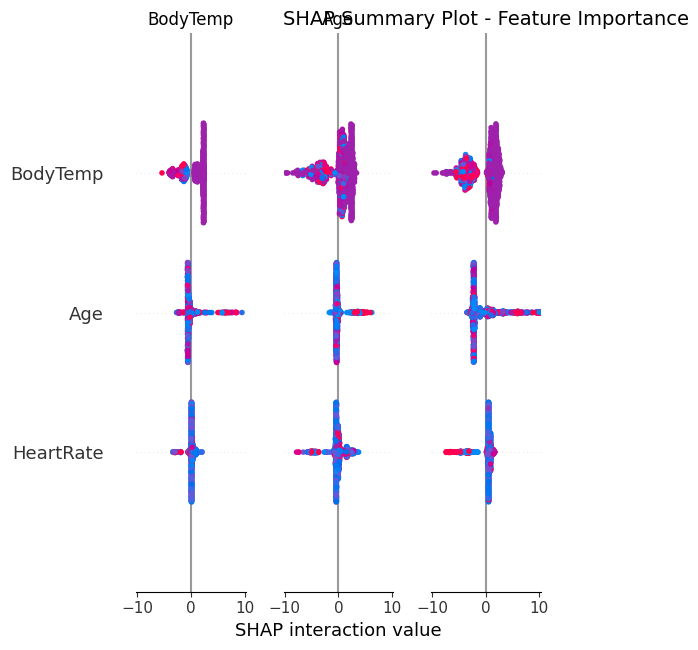

✅ shap_summary_plot.png saved


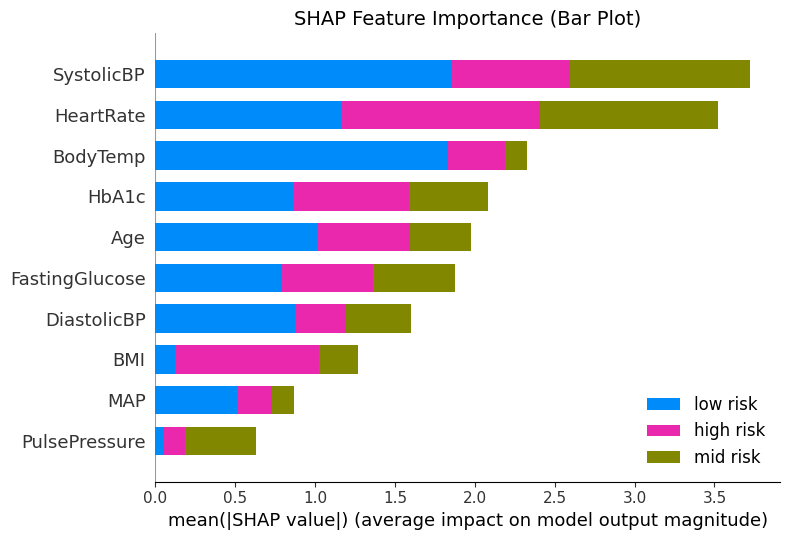

✅ shap_bar_plot.png saved


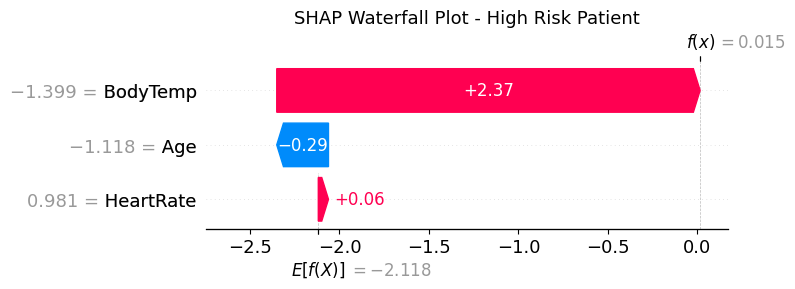

✅ shap_waterfall_highrisk.png saved

✅ SHAP Explainability Completed Successfully!


In [5]:
# ============================================================
# SHAP Explainability - Complete Self-Contained Code
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from lightgbm import LGBMClassifier
import shap
import warnings
warnings.filterwarnings('ignore')

# ====================== 1. LOAD DUET DATA ======================
df = pd.read_csv("Maternal_Risk_DUET_Cleaned.csv")

le = LabelEncoder()
df['RiskLevel'] = le.fit_transform(df['RiskLevel'])
print("Classes:", le.classes_)

X = df.drop('RiskLevel', axis=1)
y = df['RiskLevel']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ====================== 2. TRAIN LightGBM ======================
lgbm = LGBMClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=7,
    random_state=42, n_jobs=-1, verbose=-1
)
lgbm.fit(X_train_scaled, y_train)
print("✅ LightGBM trained on DUET")

# ====================== 3. SHAP ======================
print("Generating SHAP values...")
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test_scaled)

# ----- Summary Plot -----
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values, X_test_scaled,
    feature_names=list(X.columns),
    class_names=list(le.classes_),
    show=False
)
plt.title("SHAP Summary Plot - Feature Importance", fontsize=14)
plt.tight_layout()
plt.savefig("shap_summary_plot.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ shap_summary_plot.png saved")

# ----- Bar Plot -----
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values, X_test_scaled,
    feature_names=list(X.columns),
    class_names=list(le.classes_),
    plot_type="bar",
    show=False
)
plt.title("SHAP Feature Importance (Bar Plot)", fontsize=14)
plt.tight_layout()
plt.savefig("shap_bar_plot.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ shap_bar_plot.png saved")

# ----- Waterfall Plot (High-Risk) -----
high_risk_idx = list(le.classes_).index('high risk')
high_risk_samples = np.where(y_test == high_risk_idx)[0]

if len(high_risk_samples) > 0:
    sample_idx = high_risk_samples[0]
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values[high_risk_idx][sample_idx],
            base_values=explainer.expected_value[high_risk_idx],
            data=X_test_scaled[sample_idx],
            feature_names=list(X.columns)
        ),
        show=False
    )
    plt.title("SHAP Waterfall Plot - High Risk Patient", fontsize=13)
    plt.tight_layout()
    plt.savefig("shap_waterfall_highrisk.png", dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ shap_waterfall_highrisk.png saved")
else:
    print("No high-risk sample found in test set.")

print("\n✅ SHAP Explainability Completed Successfully!")

Classes: ['high risk', 'low risk', 'mid risk']
Training models...
✅ Models trained


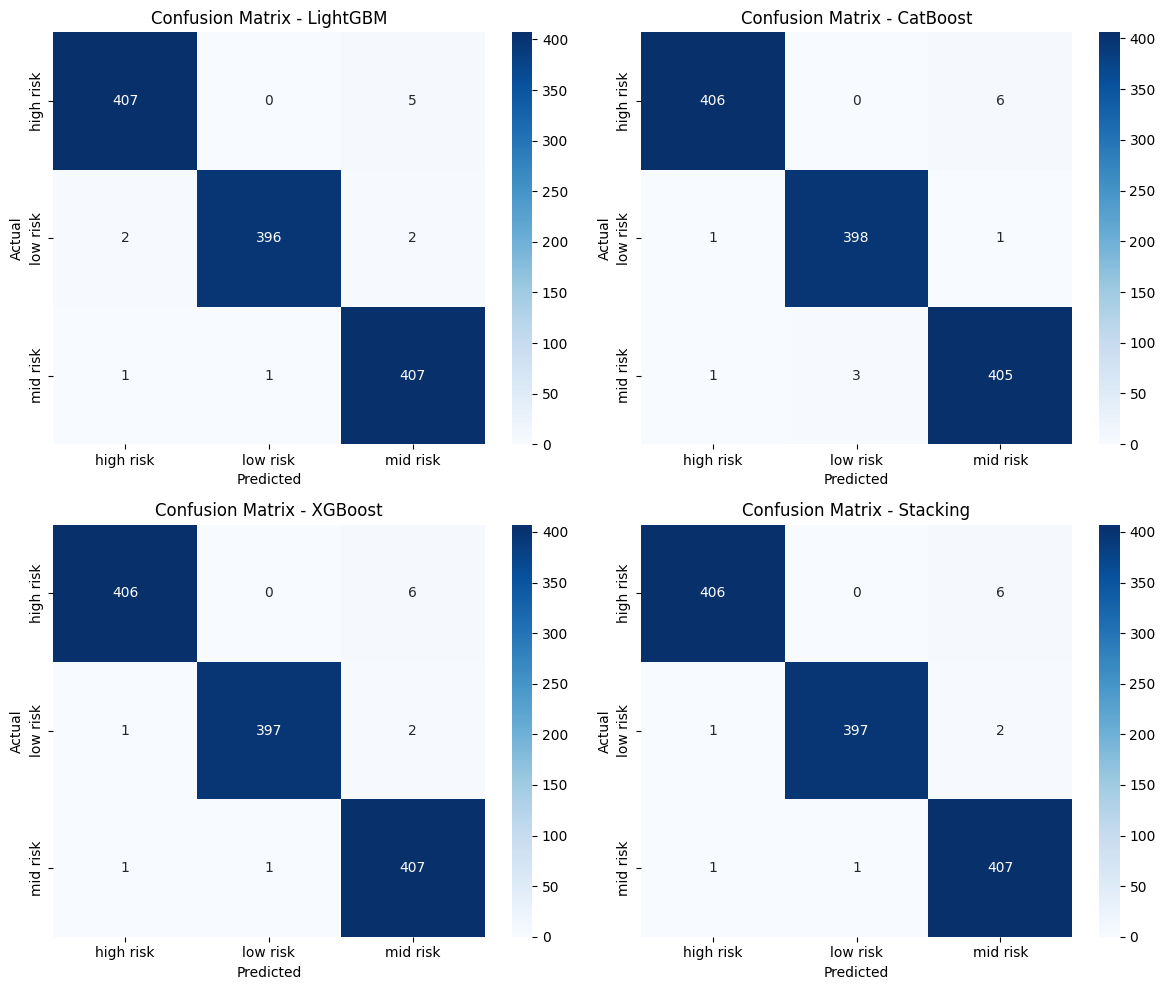

✅ confusion_matrices.png saved


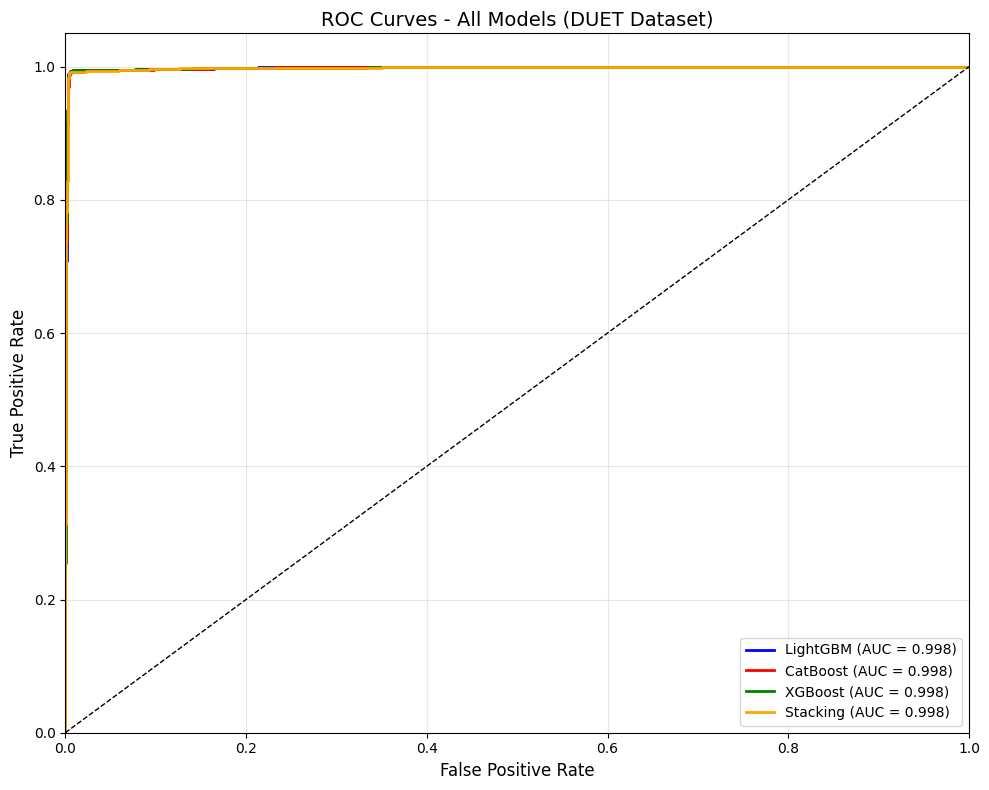

✅ roc_curves.png saved

✅ Models saved:
  - model_lightgbm.pkl
  - model_catboost.pkl
  - model_xgboost.pkl
  - model_stacking.pkl
  - scaler.pkl
  - label_encoder.pkl

✅ All plots and models saved successfully!


In [6]:
# ============================================================
# ROC Curve + Confusion Matrix + Model Save (.pkl)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.metrics import (confusion_matrix, roc_curve, auc,
                             classification_report, accuracy_score)
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from itertools import cycle
import warnings
warnings.filterwarnings('ignore')

# ====================== 1. LOAD & PREPARE DUET ======================
df = pd.read_csv("Maternal_Risk_DUET_Cleaned.csv")

le = LabelEncoder()
df['RiskLevel'] = le.fit_transform(df['RiskLevel'])
class_names = list(le.classes_)
print("Classes:", class_names)

X = df.drop('RiskLevel', axis=1)
y = df['RiskLevel']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ====================== 2. TRAIN MODELS ======================
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=7,
                      random_state=42, n_jobs=-1, verbose=-1)
cat  = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=7,
                          random_state=42, verbose=0)
xgb  = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                     random_state=42, n_jobs=-1, eval_metric='mlogloss')

stacking = StackingClassifier(
    estimators=[('lgbm', lgbm), ('cat', cat), ('xgb', xgb)],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5, n_jobs=-1
)

print("Training models...")
lgbm.fit(X_train_scaled, y_train)
cat.fit(X_train_scaled, y_train)
xgb.fit(X_train_scaled, y_train)
stacking.fit(X_train_scaled, y_train)
print("✅ Models trained")

models = {
    "LightGBM": lgbm,
    "CatBoost": cat,
    "XGBoost": xgb,
    "Stacking": stacking
}

# ====================== 3. CONFUSION MATRIX PLOTS ======================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[idx])
    axes[idx].set_title(f'Confusion Matrix - {name}', fontsize=12)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ confusion_matrices.png saved")

# ====================== 4. ROC CURVES (One-vs-Rest) ======================
n_classes = len(class_names)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

plt.figure(figsize=(10, 8))
colors = cycle(['blue', 'red', 'green', 'orange'])

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_scaled)
    else:
        continue

    # Macro-average ROC
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Compute micro-average
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    color = next(colors)
    plt.plot(fpr["micro"], tpr["micro"], color=color, lw=2,
             label=f'{name} (AUC = {roc_auc["micro"]:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves - All Models (DUET Dataset)', fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ roc_curves.png saved")

# ====================== 5. SAVE MODELS (.pkl) ======================
joblib.dump(lgbm, "model_lightgbm.pkl")
joblib.dump(cat, "model_catboost.pkl")
joblib.dump(xgb, "model_xgboost.pkl")
joblib.dump(stacking, "model_stacking.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(le, "label_encoder.pkl")

print("\n✅ Models saved:")
print("  - model_lightgbm.pkl")
print("  - model_catboost.pkl")
print("  - model_xgboost.pkl")
print("  - model_stacking.pkl")
print("  - scaler.pkl")
print("  - label_encoder.pkl")

print("\n✅ All plots and models saved successfully!")